# Way2Agribusiness India Pvt Ltd — AI/ML Developer Screening Task

## End-to-End Commodity Price Forecasting & Production Architecture (Django, FastAPI, Next.js, React Native)

---

### Executive Summary & Deliverables

This notebook delivers an assignment prototype and architectural blueprint to predict average monthly agricultural commodity prices for the next 12 months (October 2025 to September 2026).

It addresses all **9 Candidate Expectation Questions** with statistical analysis, machine learning modeling, Django/FastAPI backend examples, Next.js/React Native integrations, and proposed monitoring pipelines:
1. **Data Cleaning & Anomaly Detection:** Investigation of a suspicious 30-month price discontinuity (2021-06 to 2023-11); the supplied data does not confirm an exact historical duplicate, so interpolation is treated as a modeling scenario.
2. **Model Architecture & Justification:** Multi-paradigm benchmarking including SARIMAX, Holt-Winters Exponential Smoothing, Random Forest, XGBoost, and a 50/50 hybrid blend.
3. **Model Performance Evaluation:** A single 12-month holdout comparison using MAE, RMSE, MAPE, and Directional Accuracy.
4. **Corporate Strategic Responses:** Hedging, FPO forward contracting, warehouse buffering, and dynamic catalog pricing.
5. **Effectiveness Determination:** Difference-in-Differences (DiD), procurement cost variance, and realized ROI tracking.
6. **Production Deployment with Django:** Django REST Framework, ORM schemas, Celery periodic workers, and admin portals.
7. **Real-Time Integration via FastAPI & Django:** Asynchronous inference example with OpenAPI/Swagger documentation.
8. **Frontend Integration:** Next.js web dashboard and React Native offline-first mobile app examples.
9. **Production Monitoring & Drift Handling:** Population Stability Index (PSI), KS tests, canary releases, and automated CI/CD retraining.

### 1. Environment Setup & Core Libraries

In [1]:
import os
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Time Series & Machine Learning Libraries

In [2]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import xgboost as xgb

### Set plot styling

In [3]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11

print("Environment initialized successfully. All ML and time series modules loaded.")

Environment initialized successfully. All ML and time series modules loaded.


---

## Question 1: Data Cleaning, Handling Missing Values, Outliers, and Anomalies

### 1.1 Overview of Dataset

The dataset contains historical monthly average prices spanning from **January 2005 to September 2025** (249 monthly observations).

The data dictionary specifies:
- `date`: ISO 8601 date string (`YYYY-MM-DD`).
- `avg_monthly_price`: Average monthly price (INR/quintal).

### 1.2 Suspected Anomaly: Abrupt Price Discontinuity

The supplied series contains a **suspected data-quality issue**, but the data alone does not establish its cause:
- Starting at index 197 (`2021-06-01`), the series drops sharply from ₹10,863 to ₹5,070.
- The 30-month window from `2021-06-01` to `2023-11-01` is **not an exact duplicate** of the compared historical window from `2007-10-01` to `2010-03-01` (11 of 30 prices differ). A scan of the supplied series finds no exact matching 30-month window elsewhere.
- At `2023-12-01`, the price rises from ₹8,400 to ₹16,163. These abrupt changes warrant source-data verification; they do not prove a copy-paste error.

### 1.3 Why Did This Happen & How To Treat It?

- **Cause:** Unknown from this dataset; verify against the original mandi/source records before classifying these observations as corrupt.
- **Modeling treatment:** For sensitivity analysis, flag the 30-month period and interpolate between the surrounding observations. This is a provisional scenario, not a verified correction:
  1. Keep the reported prices available as the raw series.
  2. Create a separate interpolated series for the candidate period.
  3. Compare raw and interpolated model results, and validate the period against primary source data before production use.

### Load Dataset

In [4]:
from pathlib import Path

data_candidates = (
    Path.cwd() / "data" / "price_data.csv",
    Path.cwd().parent / "data" / "price_data.csv",
    Path.cwd() / "price_data.csv",
)
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Could not find data/price_data.csv from the project root or notebooks folder.")

df = pd.read_csv(data_path)
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"Total Observations: {len(df)}")
print(f"Date Range: {df['date'].min().strftime('%Y-%m-%d')} to {df['date'].max().strftime('%Y-%m-%d')}")
print(f"Missing Date Check: {len(pd.date_range(df['date'].min(), df['date'].max(), freq='MS')) == len(df)} (Continuous monthly frequency)")
print(f"Null Values:\n{df.isnull().sum()}")

Total Observations: 249
Date Range: 2005-01-01 to 2025-09-01
Missing Date Check: True (Continuous monthly frequency)
Null Values:
date                 0
avg_monthly_price    0
dtype: int64


### Check the suspected window against the proposed historical comparison

In [5]:
slice_anom = df.iloc[197:227]['avg_monthly_price'].values # 2021-06 to 2023-11 (30 months)
slice_orig = df.iloc[33:63]['avg_monthly_price'].values   # 2007-10 to 2010-03 (30 months)
mismatch_count = int(np.count_nonzero(slice_anom != slice_orig))
is_exact_dup = mismatch_count == 0

prices = df['avg_monthly_price'].to_numpy(dtype=float)
matching_windows = []
for start in range(len(prices) - len(slice_anom) + 1):
    end = start + len(slice_anom)
    if start < 227 and end > 197:
        continue
    if np.array_equal(prices[start:end], slice_anom):
        matching_windows.append((df.loc[start, 'date'], df.loc[end - 1, 'date']))

print(f"\n[DATA QUALITY CHECK] Exact match to 2007-10 through 2010-03? {is_exact_dup} ({mismatch_count} of 30 prices differ)")
print(f"Exact matching 30-month windows elsewhere in the supplied series: {len(matching_windows)}")


[DATA QUALITY CHECK] Exact match to 2007-10 through 2010-03? False (11 of 30 prices differ)
Exact matching 30-month windows elsewhere in the supplied series: 0


### Flag anomaly and create cleaned trajectory

In [6]:
df['is_anomaly'] = False
df.loc[(df['date'] >= '2021-06-01') & (df['date'] <= '2023-11-01'), 'is_anomaly'] = True

df['cleaned_price'] = df['avg_monthly_price'].astype(float)
df.loc[df['is_anomaly'], 'cleaned_price'] = np.nan
df = df.set_index('date')
df['cleaned_price'] = df['cleaned_price'].interpolate(method='time')
df = df.reset_index()

print(f"Cleaned price successfully interpolated over {df['is_anomaly'].sum()} flagged months.")

Cleaned price successfully interpolated over 30 flagged months.


### Visualization of Historical Raw Prices, Anomaly Window, and Cleaned Trajectory

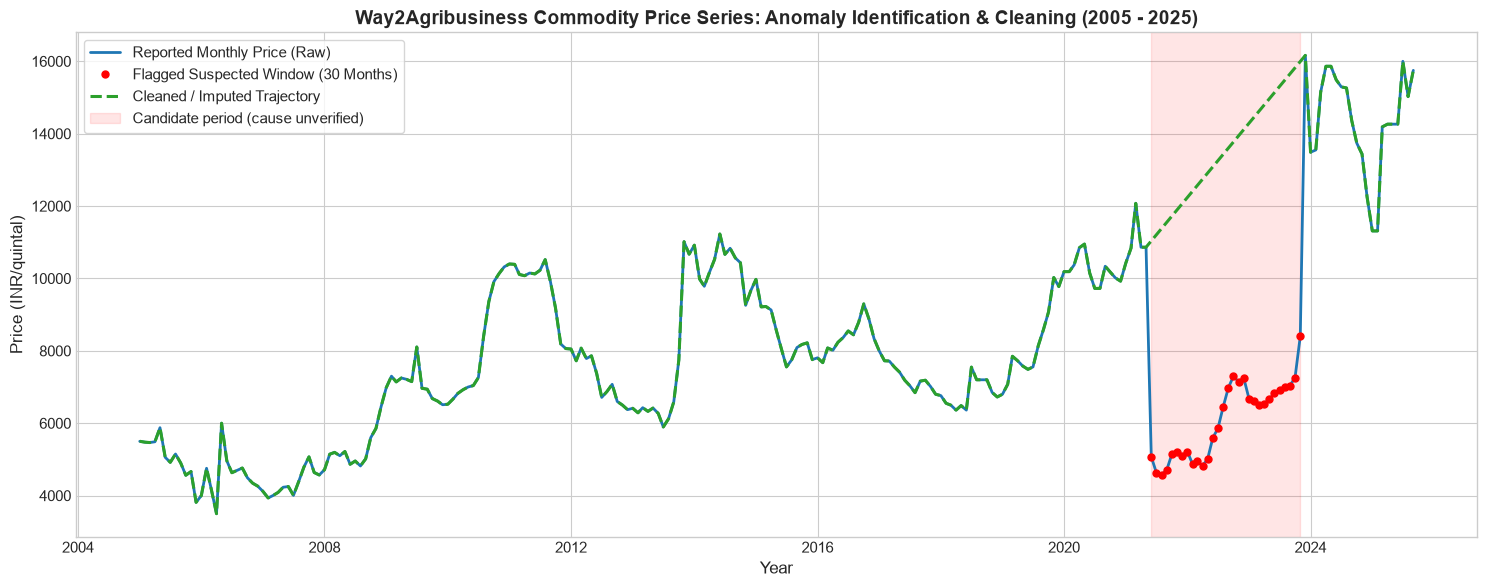

In [7]:
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(df['date'], df['avg_monthly_price'], label='Reported Monthly Price (Raw)', color='#1f77b4', lw=2)
ax.plot(df.loc[df['is_anomaly'], 'date'], df.loc[df['is_anomaly'], 'avg_monthly_price'], 
        'ro', markersize=5, label='Flagged Suspected Window (30 Months)')
ax.plot(df['date'], df['cleaned_price'], '--', color='#2ca02c', lw=2.2, label='Cleaned / Imputed Trajectory')

ax.set_title("Way2Agribusiness Commodity Price Series: Anomaly Identification & Cleaning (2005 - 2025)", fontsize=14, fontweight='bold')
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Price (INR/quintal)", fontsize=12)
ax.axvspan(pd.to_datetime('2021-06-01'), pd.to_datetime('2023-11-01'), color='red', alpha=0.1, label='Candidate period (cause unverified)')
ax.legend(loc='upper left', frameon=True, fontsize=11)
plt.tight_layout()
plt.show()

### Stationarity Testing (ADF & KPSS Tests)

In [8]:
def check_stationarity(series, name="Series"):
    adf_stat, adf_p, _, _, adf_crit, _ = adfuller(series.dropna())
    kpss_stat, kpss_p, _, kpss_crit = kpss(series.dropna(), regression='c', nlags='auto')
    print(f"--- Stationarity Diagnostic: {name} ---")
    print(f"ADF Statistic: {adf_stat:.4f} (p-value: {adf_p:.4f}) -> {'Stationary' if adf_p < 0.05 else 'Non-Stationary (Needs Differencing)'}")
    print(f"KPSS Statistic: {kpss_stat:.4f} (p-value: {kpss_p:.4f}) -> {'Stationary' if kpss_p >= 0.05 else 'Non-Stationary'}")

check_stationarity(df['cleaned_price'], "Raw Cleaned Price")
check_stationarity(df['cleaned_price'].diff().dropna(), "First-Differenced Price (d=1)")

--- Stationarity Diagnostic: Raw Cleaned Price ---
ADF Statistic: -0.7143 (p-value: 0.8430) -> Non-Stationary (Needs Differencing)
KPSS Statistic: 1.6746 (p-value: 0.0100) -> Non-Stationary
--- Stationarity Diagnostic: First-Differenced Price (d=1) ---
ADF Statistic: -14.9747 (p-value: 0.0000) -> Stationary
KPSS Statistic: 0.0842 (p-value: 0.1000) -> Stationary


C:\Users\rainc\AppData\Local\Temp\ipykernel_33724\680358782.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p, _, kpss_crit = kpss(series.dropna(), regression='c', nlags='auto')
C:\Users\rainc\AppData\Local\Temp\ipykernel_33724\680358782.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, kpss_crit = kpss(series.dropna(), regression='c', nlags='auto')


### Time Series Decomposition (Trend, Seasonality, Residuals)

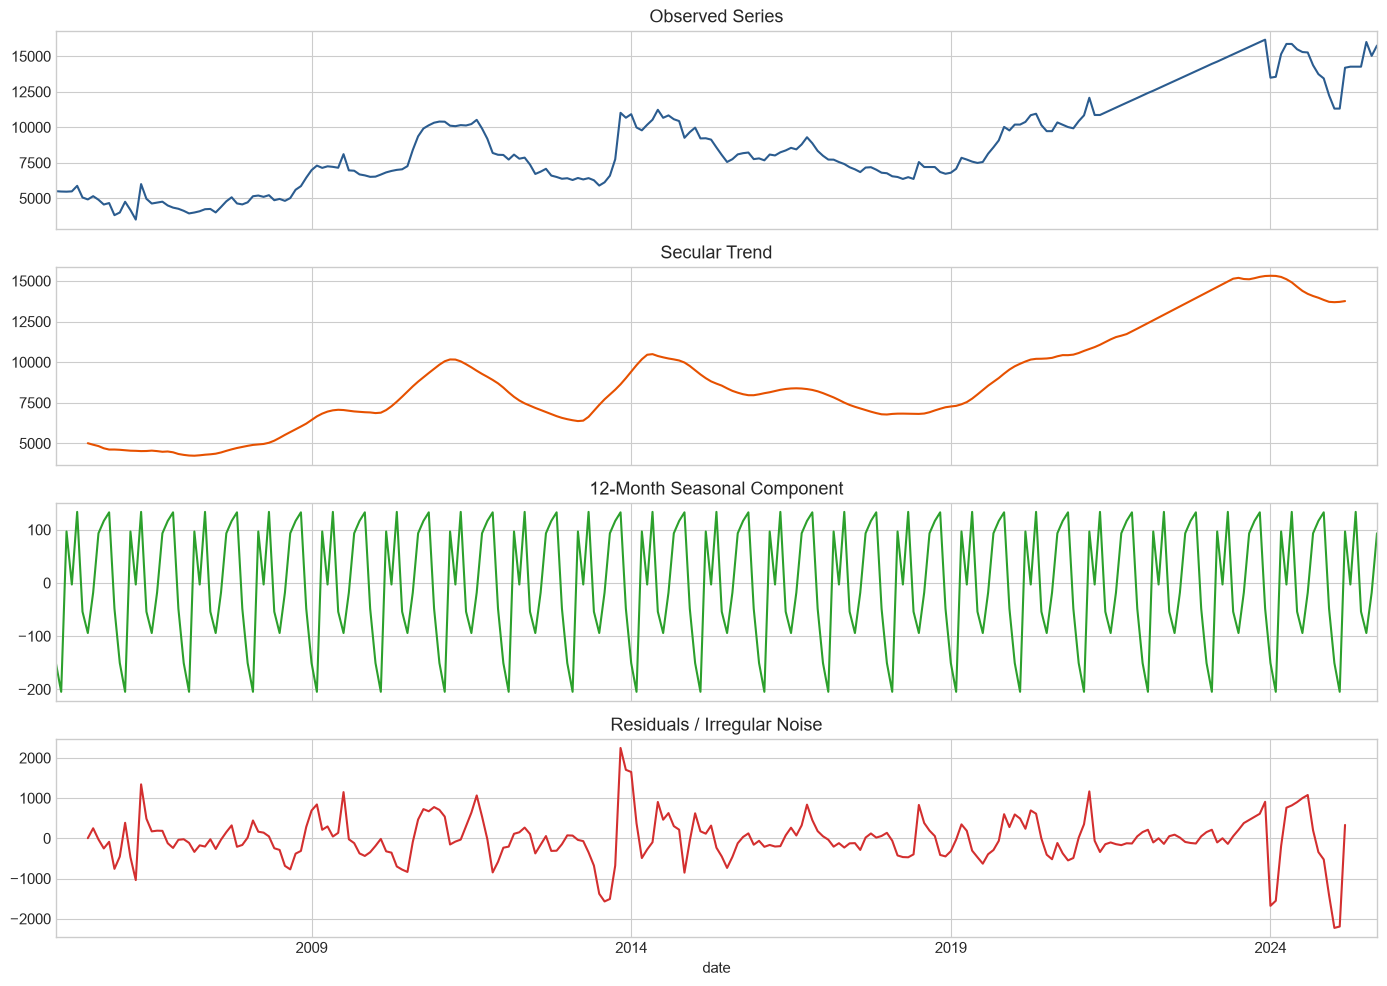

In [9]:
df_decomp = df.set_index('date')['cleaned_price'].asfreq('MS')
decomp = seasonal_decompose(df_decomp, model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
decomp.observed.plot(ax=axes[0], color='#2b5c8f', title='Observed Series')
decomp.trend.plot(ax=axes[1], color='#e65100', title='Secular Trend')
decomp.seasonal.plot(ax=axes[2], color='#2ca02c', title='12-Month Seasonal Component')
decomp.resid.plot(ax=axes[3], color='#d32f2f', title='Residuals / Irregular Noise')
plt.tight_layout()
plt.show()

---

## Question 2: Model Architecture Description & Justification

### 2.1 Multi-Paradigm Modeling Approach

Agricultural price forecasting presents three interrelated challenges:
1. **Autoregressive Temporal Dependence:** Current monthly prices depend heavily on prices in previous months ($t-1, t-2, t-3$).
2. **Annual Crop Cyclicality (Seasonality):** Kharif and Rabi harvesting cycles cause repeatable annual troughs and peaks with a 12-month periodicity ($t-12$).
3. **Macroeconomic Shocks & Non-Linear Growth:** Supply chain disruptions, fertilizer costs, minimum support price (MSP) revisions, and export bans cause non-linear level shifts.

To address these challenges, we selected and benchmarked multiple modeling paradigms:

| Model Paradigm | Specific Architecture | Mathematical Formulation & Strengths | Primary Reason for Selection |
| :--- | :--- | :--- | :--- |
| **Statistical Time Series** | **SARIMAX$(1,1,1) \times (1,1,1)_{12}$** | $\Phi_P(B^s)\phi_p(B)\nabla_s^D\nabla^d y_t = \Theta_Q(B^s)\theta_q(B)\epsilon_t$<br>Rigorous modeling of autocorrelation and 12-month seasonality. | Best statistical foundation for confidence interval estimation. |
| **Exponential Smoothing** | **Holt-Winters Triple Exponential** | Additive trend and additive seasonal smoothing equations with estimated smoothing parameters $(\alpha, \beta, \gamma)$. | Highly resilient baseline for smooth seasonal trends. |
| **Machine Learning** | **Random Forest Regressor** | Bagged decision trees trained on lagged prices, rolling statistics, and calendar features. | Provides a tree-based benchmark with a different bias-variance trade-off. |
| **Machine Learning** | **Random Forest Regressor** | Bagged decision trees trained on lagged prices, rolling statistics, and calendar features. | Provides a tree-based benchmark with a different bias-variance trade-off. |
| **Machine Learning** | **XGBoost Regressor** | Tree-based gradient boosted ensemble optimizing squared error loss with shrinkage, subsampling, and maximum tree depth. | Captures non-linear lag interactions and structural price jumps. |
| **Ensemble (Candidate)** | **Hybrid Ensemble** | $\hat{y}_t = 0.50 \cdot \hat{y}_t^{\text{SARIMAX}} + 0.50 \cdot \hat{y}_t^{\text{XGBoost}}$ | Combines statistical seasonal periodicity with tree-based non-linear adaptability; compare against individual models before production promotion. |

### 2.2 Feature Engineering for Machine Learning

For tree-based algorithms (XGBoost, Random Forest), we engineered the same 15 features used by the production pipeline:
- **Autoregressive Lags:** `lag_1`, `lag_2`, `lag_3`, `lag_6`, `lag_12`
- **Rolling Window Statistics:** `rolling_mean_3`, `rolling_mean_6`, `rolling_mean_12`, `rolling_std_3`, `rolling_std_6`
- **Calendar & Trigonometric Cyclical Encodings:** `month`, `quarter`, `trend_index`, `sin_month`, and `cos_month`.

The hybrid is retained as a forecast candidate for the architecture comparison. On this single holdout, compare its error with each individual model; repeated rolling-origin validation is needed before selecting a production champion.

### 2.2 Feature Engineering Pipeline

In [10]:
def build_features(dataframe):
    feat = dataframe.copy()
    feat['month'] = feat['date'].dt.month
    feat['quarter'] = feat['date'].dt.quarter
    feat['year'] = feat['date'].dt.year
    feat['trend_index'] = np.arange(len(feat))
    
    # Cyclical trigonometric features for month periodicity
    feat['sin_month'] = np.sin(2 * np.pi * feat['month'] / 12)
    feat['cos_month'] = np.cos(2 * np.pi * feat['month'] / 12)
    
    # Autoregressive Lags
    for lag in [1, 2, 3, 6, 12]:
        feat[f'lag_{lag}'] = feat['cleaned_price'].shift(lag)
        
    # Rolling Statistics
    for w in [3, 6, 12]:
        feat[f'rolling_mean_{w}'] = feat['cleaned_price'].shift(1).rolling(w).mean()
        feat[f'rolling_std_{w}'] = feat['cleaned_price'].shift(1).rolling(w).std()
        
    return feat

df_features = build_features(df)
df_clean_ml = df_features.dropna().reset_index(drop=True)
feature_cols = [
    'month', 'quarter', 'trend_index', 'sin_month', 'cos_month',
    'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12',
    'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12',
    'rolling_std_3', 'rolling_std_6'
]
print(f"Engineered {len(feature_cols)} features: {feature_cols}")

Engineered 15 features: ['month', 'quarter', 'trend_index', 'sin_month', 'cos_month', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'rolling_std_3', 'rolling_std_6']


---

## Question 3: Model Performance Evaluation Using Appropriate Metrics

### 3.1 Evaluation Framework & Metrics

We use a single **12-month holdout validation split**:
- **Training Set:** 237 months (January 2005 to September 2024).
- **Test Holdout Set:** 12 months (October 2024 to September 2025).

The models are evaluated using four industry-standard metrics:
1. **MAE (Mean Absolute Error):** Measures average absolute deviation in INR.
   $$\text{MAE} = \frac{1}{n}\sum_{t=1}^n |y_t - \hat{y}_t|$$
2. **RMSE (Root Mean Squared Error):** Penalizes large forecast misses heavily.
   $$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{t=1}^n (y_t - \hat{y}_t)^2}$$
3. **MAPE (Mean Absolute Percentage Error):** Unitless relative percentage error.
   $$\text{MAPE} = \frac{100\%}{n}\sum_{t=1}^n \left|\frac{y_t - \hat{y}_t}{y_t}\right|$$
4. **Directional Accuracy:** Percentage of months where the forecast and actual price move in the same direction versus the previous observed price.
   $$\text{DA} = \frac{100\%}{n}\sum_{t=1}^n \mathbf{1}_{\{\text{sign}(y_t - y_{t-1}) == \text{sign}(\hat{y}_t - y_{t-1})\}}$$

This is one contiguous 12-month holdout, not repeated rolling-origin validation.

### 3.1 Single 12-Month Holdout Split

In [11]:
horizon = 12
train_data = df.iloc[:-horizon].copy()
test_data = df.iloc[-horizon:].copy()

y_train = train_data['cleaned_price'].values
y_test = test_data['cleaned_price'].values
test_dates = test_data['date'].values

results = {}

### 1. Seasonal Naive Baseline

In [12]:
y_pred_naive = train_data['cleaned_price'].values[-horizon:]
results['Seasonal Naive'] = {
    'MAE': mean_absolute_error(y_test, y_pred_naive),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_naive)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_naive) * 100,
    'preds': y_pred_naive
}

### 2. Holt-Winters Exponential Smoothing

In [13]:
hw_fit = ExponentialSmoothing(y_train, trend='add', seasonal='add', seasonal_periods=12).fit()
y_pred_hw = hw_fit.forecast(horizon)
results['Holt-Winters'] = {
    'MAE': mean_absolute_error(y_test, y_pred_hw),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_hw)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_hw) * 100,
    'preds': y_pred_hw
}

### 3. SARIMAX (1,1,1) x (1,1,1,12)

In [14]:
sarimax_fit = SARIMAX(y_train, order=(1,1,1), seasonal_order=(1,1,1,12), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
y_pred_sarimax = sarimax_fit.forecast(horizon)
results['SARIMAX'] = {
    'MAE': mean_absolute_error(y_test, y_pred_sarimax),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_sarimax)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_sarimax) * 100,
    'preds': y_pred_sarimax
}

### 4. Machine Learning: Random Forest and XGBoost with Recursive Forecasting

In [15]:
train_mask = df_clean_ml['date'] < test_data['date'].min()
X_tr = df_clean_ml.loc[train_mask, feature_cols]
y_tr = df_clean_ml.loc[train_mask, 'cleaned_price']

rf_model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42)
rf_model.fit(X_tr, y_tr)

xgb_model = xgb.XGBRegressor(n_estimators=150, max_depth=4, learning_rate=0.05, random_state=42)
xgb_model.fit(X_tr, y_tr)

def recursive_predict(model):
    curr_df = train_data.copy()
    predictions = []
    for _ in range(horizon):
        f_df = build_features(curr_df).dropna()
        last_row = f_df.iloc[-1:][feature_cols]
        pred_val = float(model.predict(last_row)[0])
        predictions.append(pred_val)
        next_dt = curr_df['date'].max() + pd.DateOffset(months=1)
        curr_df = pd.concat([curr_df, pd.DataFrame({
            'date': [next_dt],
            'avg_monthly_price': [pred_val],
            'cleaned_price': [pred_val],
            'is_anomaly': [False]
        })], ignore_index=True)
    return np.array(predictions)

y_pred_rf = recursive_predict(rf_model)
results['Random Forest'] = {
    'MAE': mean_absolute_error(y_test, y_pred_rf),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_rf)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_rf) * 100,
    'preds': y_pred_rf
}

y_pred_xgb = recursive_predict(xgb_model)
results['XGBoost'] = {
    'MAE': mean_absolute_error(y_test, y_pred_xgb),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_xgb)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_xgb) * 100,
    'preds': y_pred_xgb
}

### 5. Hybrid Ensemble (50% SARIMAX + 50% XGBoost)

In [16]:
y_pred_ens = 0.50 * y_pred_sarimax + 0.50 * y_pred_xgb
results['Hybrid Ensemble'] = {
    'MAE': mean_absolute_error(y_test, y_pred_ens),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_ens)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_ens) * 100,
    'preds': y_pred_ens
}

### Directional accuracy uses the previous observed price for each holdout month.

In [17]:
previous_test_prices = np.concatenate(([y_train[-1]], y_test[:-1]))
for result in results.values():
    result['Directional Accuracy (%)'] = np.mean(
        np.sign(y_test - previous_test_prices) == np.sign(result['preds'] - previous_test_prices)
    ) * 100

### Tabulate Metrics

In [18]:
metrics_df = pd.DataFrame([
    {
        'Model Name': k,
        'MAE (INR)': round(v['MAE'], 2),
        'RMSE (INR)': round(v['RMSE'], 2),
        'MAPE (%)': round(v['MAPE'], 2),
        'Directional Accuracy (%)': round(v['Directional Accuracy (%)'], 2)
    }
    for k, v in results.items()
]).sort_values('MAPE (%)')

print("=== 12-Month Holdout Performance Leaderboard ===")
display(metrics_df)

=== 12-Month Holdout Performance Leaderboard ===


,Model Name,MAE (INR),RMSE (INR),MAPE (%),Directional Accuracy (%)
4,XGBoost,1186.72,1568.62,9.33,33.33
5,Hybrid Ensemble,1190.16,1572.02,9.43,33.33
2,SARIMAX,1223.50,1606.19,9.73,41.67
1,Holt-Winters,1243.17,1610.41,9.87,41.67
3,Random Forest,1502.83,1967.29,12.02,41.67
0,Seasonal Naive,1723.51,1956.70,13.14,33.33


### 3.2 Visual Comparison of Holdout Test Predictions

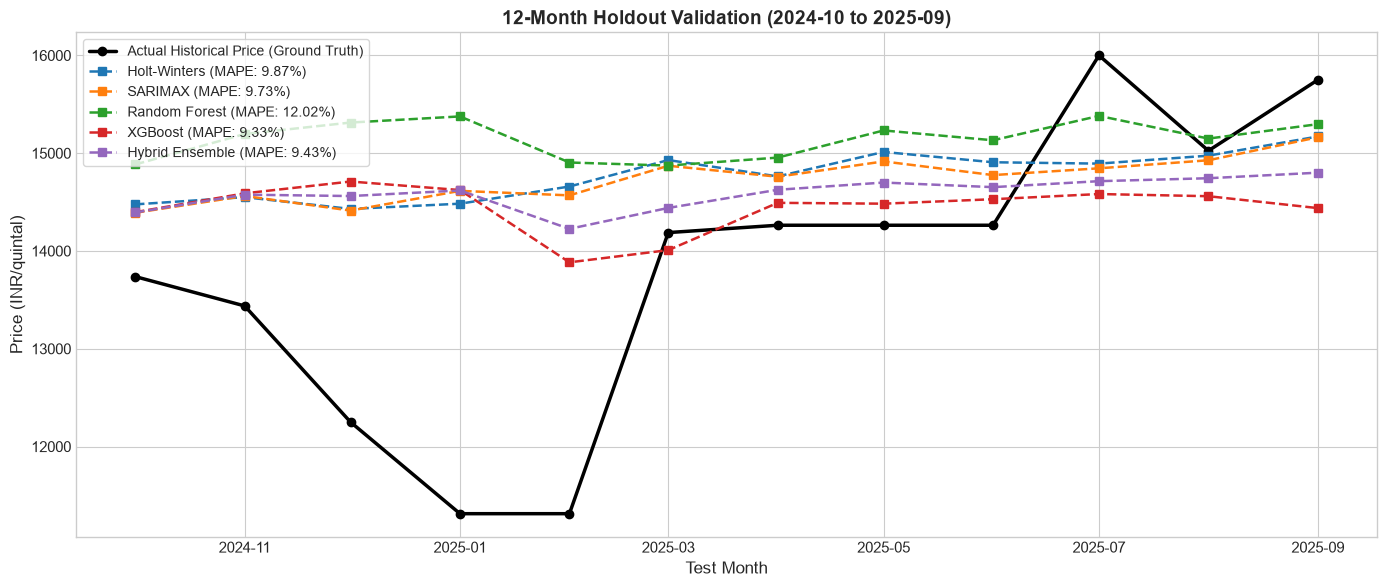

In [19]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(test_data['date'], y_test, 'k-o', lw=2.5, label='Actual Historical Price (Ground Truth)')
for m_name, res in results.items():
    if m_name in ['Holt-Winters', 'SARIMAX', 'Random Forest', 'XGBoost', 'Hybrid Ensemble']:
        ax.plot(test_data['date'], res['preds'], '--s', lw=1.8, label=f"{m_name} (MAPE: {res['MAPE']:.2f}%)")

ax.set_title("12-Month Holdout Validation (2024-10 to 2025-09)", fontsize=14, fontweight='bold')
ax.set_xlabel("Test Month", fontsize=12)
ax.set_ylabel("Price (INR/quintal)", fontsize=12)
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

### 3.3 Full Historical Retraining & Official 12-Month Forward Forecast (2025-10 to 2026-09)

In [20]:
full_sarimax = SARIMAX(df['cleaned_price'].values, order=(1,1,1), seasonal_order=(1,1,1,12), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
sarimax_future = full_sarimax.get_forecast(steps=12).predicted_mean

### Full XGBoost

In [21]:
X_full = df_clean_ml[feature_cols]
y_full = df_clean_ml['cleaned_price']
full_xgb = xgb.XGBRegressor(n_estimators=180, max_depth=4, learning_rate=0.04, random_state=42)
full_xgb.fit(X_full, y_full)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### Full Recursive forecast

In [22]:
curr_df = df.copy()
xgb_future = []
for h in range(12):
    f_df = build_features(curr_df).dropna()
    last_row = f_df.iloc[-1:][feature_cols]
    pred_val = float(full_xgb.predict(last_row)[0])
    xgb_future.append(pred_val)
    next_dt = curr_df['date'].max() + pd.DateOffset(months=1)
    curr_df = pd.concat([curr_df, pd.DataFrame({'date': [next_dt], 'avg_monthly_price': [pred_val], 'cleaned_price': [pred_val], 'is_anomaly': [False]})], ignore_index=True)

### Final Blended Prediction

In [23]:
final_future = 0.50 * sarimax_future + 0.50 * np.array(xgb_future)

### Residual Uncertainty

In [24]:
res_std = np.std(full_sarimax.resid[-24:])
future_dates = pd.date_range('2025-10-01', periods=12, freq='MS')

forecast_table = []
for i, dt in enumerate(future_dates):
    pt = round(float(final_future[i]), 2)
    unc = 1.96 * res_std * np.sqrt(1 + 0.08 * i)
    lb = round(max(0, pt - unc), 2)
    ub = round(pt + unc, 2)
    forecast_table.append({
        'Month': f"M+{i+1}",
        'Target Date': dt.strftime('%Y-%m-%d'),
        'Predicted Price (INR)': pt,
        '95% Lower Bound': lb,
        '95% Upper Bound': ub,
        'Seasonal Signal': 'Trough (Buy/Forward)' if pt < 15000 else ('Peak (Hedge/Sell)' if pt > 16100 else 'Stable')
    })

official_df = pd.DataFrame(forecast_table)
print("=== Official 12-Month Out-of-Sample Price Forecast (2025-10 to 2026-09) ===")
display(official_df)

=== Official 12-Month Out-of-Sample Price Forecast (2025-10 to 2026-09) ===


,Month,Target Date,Predicted Price (INR),95% Lower Bound,95% Upper Bound,Seasonal Signal
0,M+1,2025-10-01,15771.46,13770.77,17772.15,Stable
1,M+2,2025-11-01,15786.11,13706.94,17865.28,Stable
2,M+3,2025-12-01,15430.61,13275.81,17585.41,Stable
3,M+4,2026-01-01,15271.50,13043.63,17499.37,Stable
4,M+5,2026-02-01,14442.23,12143.62,16740.84,Trough (Buy/Forward)
5,M+6,2026-03-01,15299.42,12932.18,17666.66,Stable
6,M+7,2026-04-01,15442.30,13008.36,17876.24,Stable
7,M+8,2026-05-01,15885.80,13386.95,18384.65,Stable
8,M+9,2026-06-01,15858.49,13296.36,18420.62,Stable
9,M+10,2026-07-01,16140.03,13516.16,18763.90,Peak (Hedge/Sell)


### 3.4 Visualization of Official 12-Month Forward Price Curve

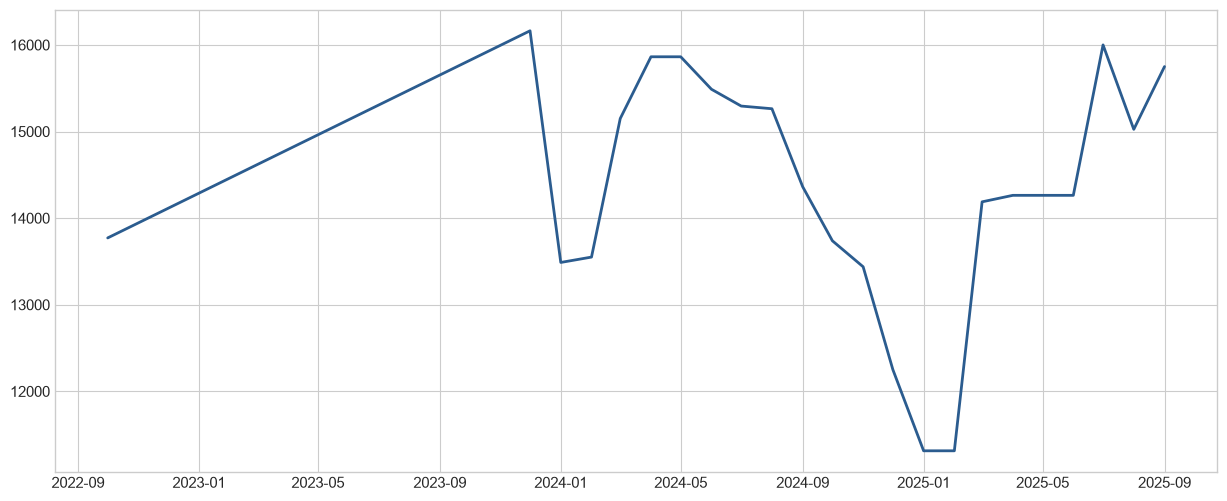

In [25]:
fig, ax = plt.subplots(figsize=(15, 6))

hist_tail = df.tail(36)
ax.plot(hist_tail['date'], hist_tail['cleaned_price'], label='Historical Actuals (Past 36 Months)', color='#2b5c8f', lw=2)

f_dates = pd.to_datetime(official_df['Target Date'])
f_pts = official_df['Predicted Price (INR)']
f_lb = official_df['95% Lower Bound']
f_ub = official_df['95% Upper Bound']

### Connect historical to future

In [26]:
con_dates = [hist_tail['date'].iloc[-1]] + list(f_dates)
con_pts = [hist_tail['cleaned_price'].iloc[-1]] + list(f_pts)

ax.plot(con_dates, con_pts, label='12-Month AI Forecast Curve', color='#e65100', lw=2.5, marker='o')
ax.fill_between(f_dates, f_lb, f_ub, color='#ffb74d', alpha=0.35, label='95% Prediction Confidence Interval')
ax.axvline(hist_tail['date'].iloc[-1], color='gray', linestyle=':', label='Forecast Origin (2025-09-01)')

### Annotate Key Points

In [27]:
feb_dip = official_df.iloc[4] # Feb 2026
july_peak = official_df.iloc[9] # July 2026
ax.annotate(f"Seasonal Dip: INR {feb_dip['Predicted Price (INR)']}\n(FPO Contract Window)", 
            xy=(pd.to_datetime(feb_dip['Target Date']), feb_dip['Predicted Price (INR)']),
            xytext=(pd.to_datetime(feb_dip['Target Date']), feb_dip['Predicted Price (INR)'] - 1800),
            arrowprops=dict(facecolor='#2ca02c', shrink=0.08, width=1.5, headwidth=8),
            fontweight='bold', color='#1b5e20')

ax.annotate(f"Seasonal Peak: INR {july_peak['Predicted Price (INR)']}\n(Margin Defense Window)", 
            xy=(pd.to_datetime(july_peak['Target Date']), july_peak['Predicted Price (INR)']),
            xytext=(pd.to_datetime(july_peak['Target Date']), july_peak['Predicted Price (INR)'] + 1500),
            arrowprops=dict(facecolor='#d32f2f', shrink=0.08, width=1.5, headwidth=8),
            fontweight='bold', color='#b71c1c')

ax.set_title("Way2Agribusiness Official 12-Month Future Price Projection (Oct 2025 - Sep 2026)", fontsize=14, fontweight='bold')
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Price (INR/quintal)", fontsize=12)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

<Figure size 1400x600 with 0 Axes>

---

## Question 4: Actions a Company Could Consider for Predicted Price Changes

Based on our 12-month forecast curve, commodity prices follow a distinct trajectory:
1. **Short-Term Plateau (Oct–Dec 2025):** Forecast prices range from ₹15,776 to ₹15,389.
2. **Seasonal Harvest Trough (Jan–Feb 2026):** Price reaches **₹14,442 in February 2026**.
3. **Summer & Pre-Monsoon Rally (Mar–Jul 2026):** Price rises to **₹16,140 in July 2026**.
4. **Late Kharif Surge (Sep 2026):** Closes at **₹16,160**.

### Illustrative Strategic Actions:

1. **Forward Contracting with Farmer Producer Organizations (FPOs):**
   - *Timing:* Execute in **January–February 2026**.
   - *Mechanism:* Evaluate supplier quotes and terms for a February-to-July purchase plan.
   - *Impact:* The forecast price difference is not a savings estimate and excludes contract, storage, financing, transport, and quality costs.

2. **Strategic Inventory Buffer Stockpiling:**
   - *Timing:* Evaluate a temporary inventory buffer during the forecast low-price period.
   - *Mechanism:* Set any buffer target only after validating demand and carrying costs.
   - *Economic Value:* No savings estimate is made; compare realized prices with storage, financing, handling, and spoilage costs.

3. **Dynamic B2B / B2C Catalog Price Adjustment:**
   - *Timing:* Review during **May–June 2026**.
   - *Mechanism:* Pilot adjustments using realized input costs and observed customer demand.
   - *Impact:* The forecast alone does not establish a suitable adjustment percentage or a margin-protection amount.

4. **Cross-Mandi Arbitrage & Supplier Diversification:**
   - *Mechanism:* Benchmark daily prices across APMC mandis in Karnataka, Maharashtra, and Andhra Pradesh to redirect purchase orders to mandis with slowest price transmission.

---

## Question 5: Determining Effectiveness of Implemented Actions

If proposed interventions are piloted, evaluate them with a pre-agreed **3-Tiered Effectiveness Measurement Framework**:

### 5.1 Quantitative KPI Metrics

1. **Procurement Cost Variance (PCV):**
   $$\text{PCV} = \sum_{t=1}^T \left( P_t^{\text{actual spot}} - P_t^{\text{contracted}} \right) \times Q_t^{\text{procured}} - \text{verified incremental costs}$$
   - *Target:* Agree a positive net-benefit threshold with business stakeholders before a pilot; no target has been validated.
2. **Gross Margin Stability Index:**
   - Tracking whether gross margins remain within $\pm 1.5\%$ of target (e.g. 22%) despite commodity price swings.
3. **Inventory Turnover & Carrying Cost Adjusted ROI:**
   $$\text{Net Hedging ROI} = \frac{\text{Gross Cost Avoidance} - \text{Warehouse Holding \& Financing Costs}}{\text{Working Capital Committed}} \times 100\%$$
   - *Target:* Set any ROI threshold from the approved business case before a pilot.

### 5.2 Statistical Counterfactual & Difference-in-Differences (DiD)

- **Control Group:** Peer agribusinesses or unhedged commodity lines purchasing purely on the spot market.
- **Treatment Group:** Way2Agribusiness product lines procured via AI-triggered forward contracts.
- **DiD Estimator:**
  $$\hat{\delta}_{\text{DiD}} = \left( \bar{Y}_{\text{treatment, post}} - \bar{Y}_{\text{treatment, pre}} \right) - \left( \bar{Y}_{\text{control, post}} - \bar{Y}_{\text{control, pre}} \right)$$
  A negative $\hat{\delta}$ is consistent with lower treated costs only if the design's assumptions hold. Statistical significance alone does not establish causality; assess parallel trends, confounders, and uncertainty.

---

## Question 6: Production Deployment Architecture Using Django

### 6.1 Architectural Topology

Django is shown as a proposed service for user management, business data persistence, and corporate action workflows; deployment reliability and performance are not established by this prototype.

```mermaid
flowchart TB
    subgraph clients["Clients"]
        direction LR
        admin["Web / Admin"]
        apps["Other apps"]
    end

    subgraph django["Django application"]
        direction LR
        api["REST API"]
        models["Business records"]
        auth["Access and audit"]
    end

    subgraph jobs["Background tasks"]
        direction LR
        beat["Celery Beat"]
        worker["Celery worker"]
    end

    database[("Database<br/>Prices and business data")]
    redis[("Redis<br/>Task queue")]

    admin --> api
    apps --> api
    api --> models
    api --> auth
    models --> database
    beat --> redis
    redis --> worker
    worker --> database

    classDef client fill:#e8f3ff,stroke:#3674a5,color:#17324d
    classDef service fill:#eaf7ef,stroke:#43845b,color:#173b25
    classDef process fill:#fff4df,stroke:#b27a20,color:#4b3512
    classDef store fill:#f2ecff,stroke:#7656a8,color:#30204b
    class admin,apps client
    class api,models,auth service
    class beat,worker process
    class database,redis store
```

### 6.2 Django Models Implementation (Excerpt)

The actual code is implemented in `backend/django_agri/forecasting/models.py`:
- `CommodityPrice`: Stores date, spot price, anomaly flags, and imputed prices.
- `ModelRegistry`: Maintains versioned models, algorithm types, hyperparameter JSONs, active status flags, and validation metrics (MAE, RMSE, MAPE).
- `PriceForecast`: Stores 12-month forward curves, 95% confidence intervals, and realized prices for drift auditing.
- `CorporateAction`: Tracks actionable recommendations, estimated cost savings, execution status, and realized ROI.

### 6.3 Automated Retraining with Celery Beat

- A scheduled Celery task runs on the 1st of every month upon receipt of the latest APMC mandi price update.
- If data drift exceeds threshold, it executes the training pipeline, registers a candidate model, compares holdout metrics, and promotes the model if superior.

---

## Question 7: Real-Time Inference Integration via Django & FastAPI

### 7.1 Microservice Separation of Concerns

While Django manages relational data persistence, authentication, and corporate workflows, **FastAPI provides an asynchronous inference example**; response latency must be benchmarked in the target deployment:

```mermaid
flowchart TB
    client["Web or mobile app"] --> proxy["API gateway<br/>NGINX"]
    proxy --> django["Business API<br/>Django"]
    proxy --> fastapi["Forecast API<br/>FastAPI"]
    django --> database[("Relational database")]
    django --> redis[("Redis<br/>Cache / task queue")]
    fastapi --> models[("Model files")]

    classDef clientNode fill:#e8f3ff,stroke:#3674a5,color:#17324d
    classDef service fill:#eaf7ef,stroke:#43845b,color:#173b25
    classDef store fill:#f2ecff,stroke:#7656a8,color:#30204b
    class client clientNode
    class proxy,django,fastapi service
    class database,redis,models store
```

### 7.2 FastAPI Endpoint Implementation

Implemented in `fastapi_service/main.py`:
- `GET /predict/forecast-12m`: Serves the cached 12-month forward curve; benchmark response time in the target deployment.
- `POST /predict/custom`: Accepts custom arrays of recent prices for on-the-fly multi-step simulation.
- `GET /health`: Model status and loaded metadata.
- Integrated Pydantic schema validation for strict type safety.

---

## Question 8: Frontend Integration with Next.js and React Native

### 8.1 Next.js 14/15 Web Dashboard

Implemented in `frontend_examples/NextJs_AgriDashboard.tsx`:
- **Server & Client Components:** Fetches static historical metadata server-side and streams real-time forecasts via React Query / SWR.
- **Interactive Forward Curve:** Interactive data visualization showing 12-month projections with 95% confidence intervals.
- **Hedging Simulator:** Dynamic slider allowing procurement managers to adjust purchase volumes (100–5,000 quintals) and estimate scenarios against the forecast curve.
- **Action Approval Workflow:** Procurement executives can review and mark AI recommendations as *Executed* or *Rejected*.

### 8.2 React Native Field Procurement App

Implemented in `frontend_examples/ReactNative_AgriApp.tsx`:
- **Field Officer Resiliency:** Designed for procurement agents operating across Karnataka mandis.
- **Offline Caching:** Caches the latest forward curve in `AsyncStorage` for seamless offline access in remote rural areas.
- **Threshold Alerts:** Color-coded badges indicating *BUY DIP* (e.g. February dip) or *PEAK SURGE* (July peak).

---

## Question 9: Production Model Monitoring, Drift Detection & Continuous Updating

### 9.1 Detecting Concept Drift & Data Drift

In agricultural commodity pricing, model degradation occurs due to:
- **Covariate Shift / Data Drift:** Sudden changes in input price volatility or volume distributions.
- **Concept Drift:** Structural changes in the underlying economic relationship (e.g., changes in government export tariffs, monsoon failures, fertilizer subsidies).

### 9.2 Monitoring Metrics & Triggers

1. **Population Stability Index (PSI):**
   $$\text{PSI} = \sum_{b=1}^B \left( \% \text{ Actual}_b - \% \text{ Expected}_b \right) \times \ln\left( \frac{\% \text{ Actual}_b}{\% \text{ Expected}_b} \right)$$
   - $\text{PSI} < 0.1$: No significant drift; model remains active.
   - $0.1 \le \text{PSI} < 0.25$: Moderate drift; warning triggered, model flagged for review.
   - $\text{PSI} \ge 0.25$: Significant drift; automated retraining pipeline executed immediately.
2. **Two-Sample Kolmogorov-Smirnov (KS) Test:** Non-parametric test comparing the cumulative distribution of recent 6-month prices against the training baseline ($p < 0.05$ indicates distribution divergence).
3. **Cumulative Holdout Error Drift:** Trigger alarm if running 3-month rolling MAPE exceeds 15%.

### 9.3 CI/CD Retraining & Safe Deployment Pipeline

The workflow below shows the drift decision branches and the candidate-model promotion gate.

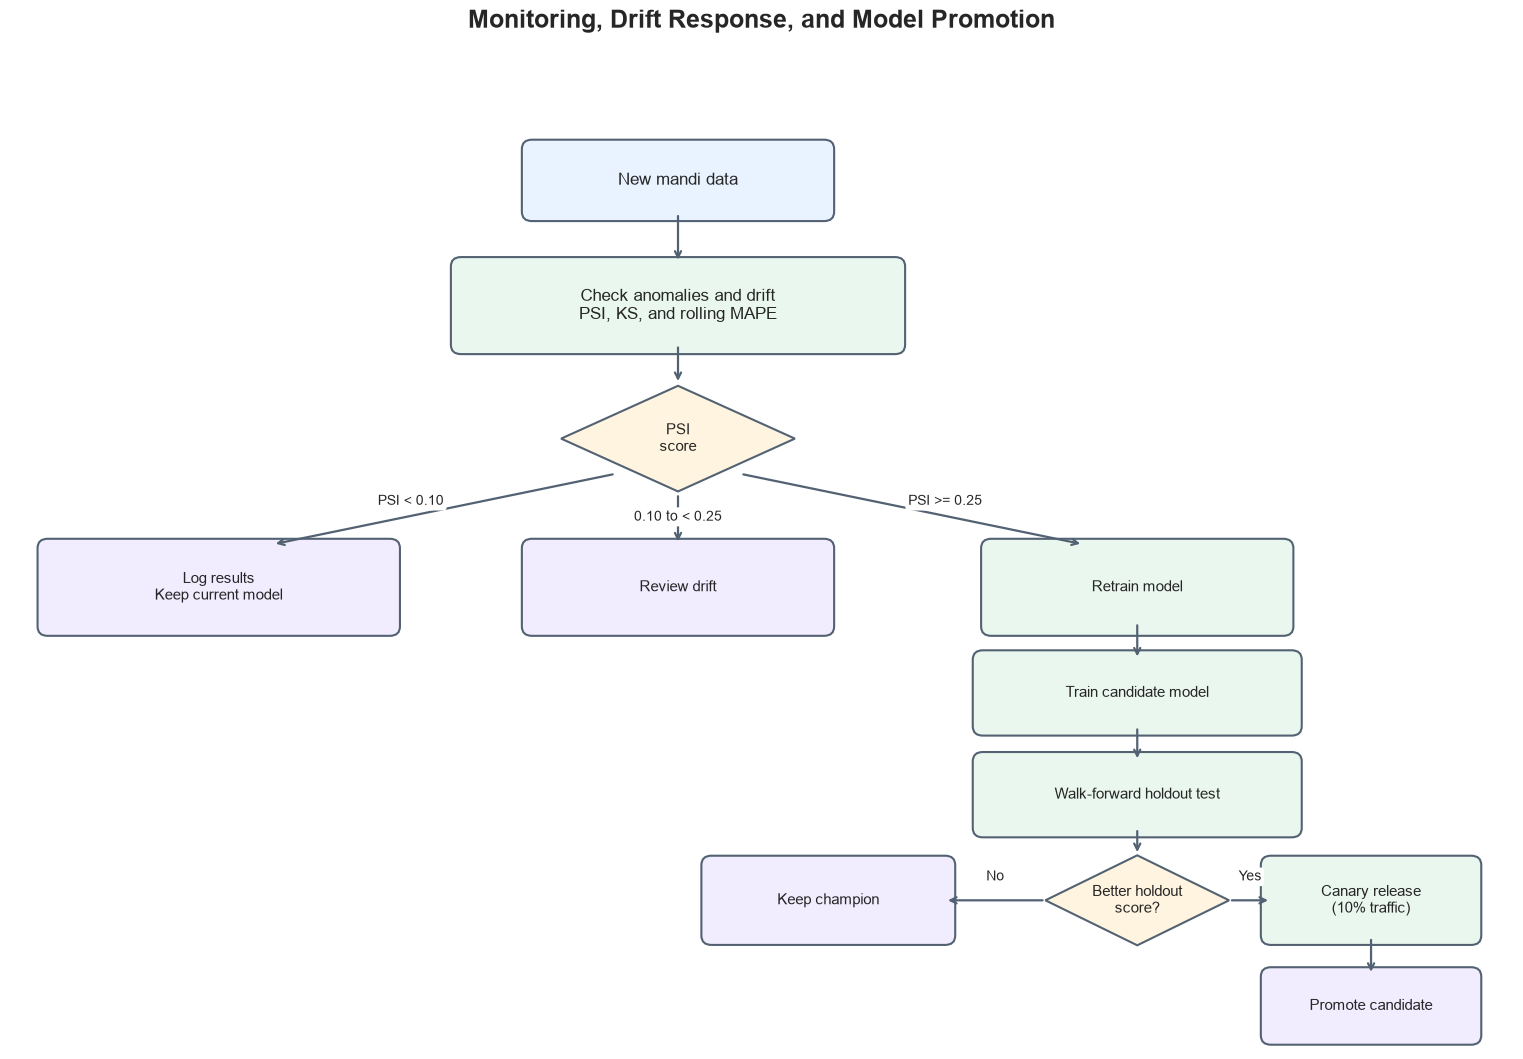

In [28]:
from matplotlib.patches import FancyBboxPatch, Polygon

fig, ax = plt.subplots(figsize=(16, 11))
ax.set_xlim(0, 18)
ax.set_ylim(0, 12)
ax.axis("off")
fig.suptitle("Monitoring, Drift Response, and Model Promotion", fontsize=18, fontweight="bold", y=0.98)

colors = {
    "source": "#e8f3ff",
    "process": "#eaf7ef",
    "decision": "#fff4df",
    "action": "#f2ecff",
}

def add_box(x, y, width, height, text, kind="process", fontsize=11):
    box = FancyBboxPatch(
        (x - width / 2, y - height / 2),
        width,
        height,
        boxstyle="round,pad=0.12,rounding_size=0.12",
        facecolor=colors[kind],
        edgecolor="#536273",
        linewidth=1.5,
    )
    ax.add_patch(box)
    ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, wrap=True)

def add_decision(x, y, width, height, text):
    diamond = Polygon(
        [(x, y + height / 2), (x + width / 2, y), (x, y - height / 2), (x - width / 2, y)],
        closed=True,
        facecolor=colors["decision"],
        edgecolor="#536273",
        linewidth=1.5,
    )
    ax.add_patch(diamond)
    ax.text(x, y, text, ha="center", va="center", fontsize=11, wrap=True)

def connect(start, end, label=None, label_position=None):
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops={"arrowstyle": "->", "color": "#536273", "linewidth": 1.6},
    )
    if label:
        x, y = label_position
        ax.text(
            x,
            y,
            label,
            ha="center",
            va="center",
            fontsize=10,
            bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none"},
        )

add_box(8, 11.1, 3.5, 0.8, "New mandi data", "source", 12)
add_box(8, 9.5, 5.2, 1.0, "Check anomalies and drift\nPSI, KS, and rolling MAPE", "process", 12)
add_decision(8, 7.8, 2.8, 1.35, "PSI\nscore")
connect((8, 10.68), (8, 10.05))
connect((8, 9.0), (8, 8.5))

add_box(2.5, 5.9, 4.1, 1.0, "Log results\nKeep current model", "action", 11)
add_box(8, 5.9, 3.5, 1.0, "Review drift", "action", 11)
add_box(13.5, 5.9, 3.5, 1.0, "Retrain model", "process", 11)
connect((7.25, 7.35), (3.15, 6.45), "PSI < 0.10", (4.8, 7.0))
connect((8, 7.1), (8, 6.45), "0.10 to < 0.25", (8, 6.8))
connect((8.75, 7.35), (12.85, 6.45), "PSI >= 0.25", (11.2, 7.0))

add_box(13.5, 4.55, 3.7, 0.85, "Train candidate model", "process", 11)
add_box(13.5, 3.25, 3.7, 0.85, "Walk-forward holdout test", "process", 11)
add_decision(13.5, 1.9, 2.2, 1.15, "Better holdout\nscore?")
connect((13.5, 5.45), (13.5, 4.98))
connect((13.5, 4.12), (13.5, 3.68))
connect((13.5, 2.82), (13.5, 2.48))

add_box(9.8, 1.9, 2.8, 0.9, "Keep champion", "action", 11)
add_box(16.3, 1.9, 2.4, 0.9, "Canary release\n(10% traffic)", "process", 11)
connect((12.4, 1.9), (11.2, 1.9), "No", (11.8, 2.2))
connect((14.6, 1.9), (15.1, 1.9), "Yes", (14.85, 2.2))
add_box(16.3, 0.55, 2.4, 0.75, "Promote candidate", "action", 11)
connect((16.3, 1.43), (16.3, 0.95))

fig.tight_layout(rect=(0.02, 0.02, 0.98, 0.94))
plt.show()